# SINTEF exploration of the original data
This notebook reads the **original CSV files directly** and does not depend on the preprocessing notebook or its outputs. It shows data quality, temporal trends, distributions, relationships, correlation matrices, generator activity, and an optional confusion-matrix section using already saved model predictions. It does not train a model or change the raw data.

Select `.venv/bin/python` and **Run All**. Dependencies are in `requirements-baseline.txt`. Input trends cover the supplied case period, including the unlabeled test years; UC plots use only the available 2015–2022 labels. These are descriptive plots. Restrict exploration to a training period when using observations to choose features or tune models.

Sources: the task, dataset definitions, and project presentation PDFs in this folder. The task is a scheduling surrogate using supplied future input trajectories, not direct forecasting of prices or inflow.

## 1. Read the original tables and check their structure

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
import re

HORIZON = 168
VALIDATION_START = pd.Timestamp('2022-01-01', tz='UTC')
TEST_START = pd.Timestamp('2023-01-01', tz='UTC')
PROJECT_DIR = next((p.resolve() for p in [Path.cwd(), Path.cwd() / 'sintef_project']
                    if (p / 'data/kernel/Unit_commitment_decisions.csv').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open the notebook from sintef_project or set PROJECT_DIR explicitly.')
print('Reading original data from:', PROJECT_DIR / 'data/kernel')

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
plt.rcParams.update({"figure.dpi": 110})
labels = pd.read_csv(PROJECT_DIR / 'data/kernel/Unit_commitment_decisions.csv')
mapping = pd.read_csv(PROJECT_DIR / 'prediction_mapping.csv')
template = pd.read_csv(PROJECT_DIR / 'sample_submission.csv')
for frame in [labels, mapping]:
    frame['starttime'] = pd.to_datetime(frame['starttime'], utc=True)
    assert frame['Run No'].is_unique and frame['starttime'].is_unique
    assert frame['starttime'].notna().all()
    assert (frame['starttime'] == frame['starttime'].dt.floor('D')).all()
labels = labels.sort_values('starttime').reset_index(drop=True)
assert template['Run No'].is_unique
assert set(mapping['Run No']) == set(template['Run No'])
assert set(labels['Run No']).isdisjoint(mapping['Run No'])
assert (labels['starttime'] < TEST_START).all()
assert (mapping['starttime'] >= TEST_START).all()
test_cases = template[['Run No']].merge(mapping, on='Run No', how='left', validate='one_to_one')
assert test_cases['Run No'].equals(template['Run No'])

target_columns = list(template.columns.drop('Run No'))
assert set(target_columns) == {c for c in labels if c.startswith('result_committed_')}
pattern = re.compile(r'^result_committed_(.+)_t(\d+)$')
parsed = [pattern.fullmatch(c) for c in target_columns]
assert all(parsed), 'Unexpected target column name.'
generators = list(dict.fromkeys(m.group(1) for m in parsed))
assert len(generators) == 14
canonical_columns = [f'result_committed_{g}_t{h}' for g in generators for h in range(HORIZON)]
assert len(target_columns) == len(canonical_columns) == 2352
assert set(canonical_columns) == set(target_columns)
raw_y = labels[canonical_columns].to_numpy()
assert np.isfinite(raw_y).all() and np.isin(raw_y, [0, 1]).all()
# Internal axes: case, hour, generator.
y = raw_y.astype('uint8').reshape(len(labels), len(generators), HORIZON).transpose(0, 2, 1)
print(f'Labeled cases: {len(labels):,}; test cases: {len(test_cases):,}; labels: {y.shape}')
display(labels[['Run No', 'starttime']].iloc[[0, -1]])
display(test_cases.iloc[[0, -1]])
all_cases = pd.concat([labels[['Run No', 'starttime']], test_cases], ignore_index=True)
required_start = all_cases['starttime'].min()
required_end = all_cases['starttime'].max() + pd.Timedelta(hours=HORIZON)

def load_series(filename, hourly=False):
    chunks = []
    for chunk in pd.read_csv(PROJECT_DIR / 'data/kernel' / filename, chunksize=100_000):
        chunk['date'] = pd.to_datetime(chunk['date'], utc=True)
        chunk = chunk.loc[chunk['date'].between(required_start, required_end)]
        if not chunk.empty:
            chunks.append(chunk)
    if not chunks:
        raise ValueError(f'No relevant observations in {filename}')
    df = pd.concat(chunks).set_index('date').sort_index()
    assert df.index.is_unique, f'Duplicate timestamps in {filename}'
    df = df.apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
    if hourly:
        df = df.resample('h').mean()
    return df.astype('float32')

price = load_series('Historical_day_ahead_price_2015_2025.csv', hourly=True)
inflow = load_series('Historical_inflow_1958_2025.csv', hourly=True)
volume = load_series('Historical_volume_2015_2024.csv')
water = load_series('Synthetic_water_value_2015_2024.csv')
assert price.shape[1] == 1 and volume.shape[1] == water.shape[1] == 17
assert set(volume.columns) == set(water.columns)
water = water[volume.columns]
audit = pd.DataFrame([{'table': name, 'rows': len(df), 'features': df.shape[1],
                       'first_UTC': str(df.index.min()), 'last_UTC': str(df.index.max()),
                       'missing_values': int(df.isna().sum().sum())}
                      for name, df in [('price', price), ('inflow', inflow),
                                       ('volume', volume), ('water_value', water)]])
display(audit)

Reading original data from: /Users/mjosefsen/Documents/NTNU/TDT4173/github/data/kernel
Labeled cases: 2,922; test cases: 725; labels: (2922, 168, 14)


,Run No,starttime
0,1,2015-01-01 00:00:00+00:00
2921,2922,2022-12-31 00:00:00+00:00


,Run No,starttime
0,2923,2023-01-01 00:00:00+00:00
724,3647,2024-12-25 00:00:00+00:00


,table,rows,features,first_UTC,last_UTC,missing_values
0,price,87673,1,2015-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,0
1,inflow,87673,18,2015-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,0
2,volume,3654,17,2015-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,0
3,water_value,3654,17,2015-01-01 00:00:00+00:00,2025-01-01 00:00:00+00:00,0


## 2. Data quality and summary statistics
Check missing observations, negative values, and constant reservoirs before interpreting relationships. Negative electricity prices can be valid. The input documentation states that the two small reservoirs Hyljelihyl and Vatjern have storage assumed to be 50% full; constant storage there is expected. Missing hourly timestamps introduced by resampling appear as missing values.

In [2]:
quality_rows = []
for name, frame in [('price', price), ('inflow', inflow), ('volume', volume), ('water_value', water)]:
    quality_rows.append({'table': name, 'missing_cells': int(frame.isna().sum().sum()),
                         'negative_cells': int((frame < 0).sum().sum()),
                         'constant_columns': ', '.join(frame.columns[frame.nunique() <= 1]) or '(none)'})
display(pd.DataFrame(quality_rows))
display(price.describe().T)
display(inflow.describe().T[['mean', 'std', 'min', 'max']])
display(volume.describe().T[['mean', 'std', 'min', 'max']])

,table,missing_cells,negative_cells,constant_columns
0,price,0,390,(none)
1,inflow,0,0,(none)
2,volume,0,0,"Hyljelihyl, Vatjern"
3,water_value,0,0,(none)


,count,mean,std,min,25%,50%,75%,max
Day-ahead price (EUR/MWh),87673.0,58.130917,71.765907,-61.84,24.110001,36.889999,59.150002,898.25


,mean,std,min,max
Langesae,1.894452,2.622442,0.06,22.930000
Staavatn,7.796916,10.565896,0.17,87.519997
Kjelavatn,3.605799,3.682482,0.18,20.200001
Bordalsvatn,6.312932,11.423659,0.00,175.059998
Foersvatn,0.658545,1.191713,0.00,18.260000
Hyljelihyl,4.286215,7.756191,0.00,118.860001
Venemo,2.406013,4.114629,0.01,145.770004
Bitdalsvatn,5.482851,7.590322,0.18,66.370003
Songavatn,25.250160,34.955265,0.84,305.640015
Totak,11.459143,14.403622,0.47,147.570007


,mean,std,min,max
Kjelavatn,42.278923,25.714727,0.000000,86.978996
Staavatn,27.197468,20.541031,0.384000,50.167999
Langesae,54.666676,17.794533,13.701000,78.615997
Foersvatn,71.503479,33.618019,0.425000,123.084000
Venemo,16.334139,2.569263,8.703000,21.806000
Botnedalsvatn,32.279755,18.301981,0.397000,55.778000
Bitdalsvatn,78.435593,24.811958,14.874000,111.824997
Vaamarvatn,14.183276,8.782494,0.056000,26.462000
Langeidvatn,22.765779,7.896403,0.321000,33.960999
Totak,168.744186,73.130592,7.063000,259.947998


## 3. Trends over time
Aggregate the raw observations to monthly means for readable long-term plots. Input observations are counted once even though weekly cases overlap. The red line marks the start of the unlabeled test cases.

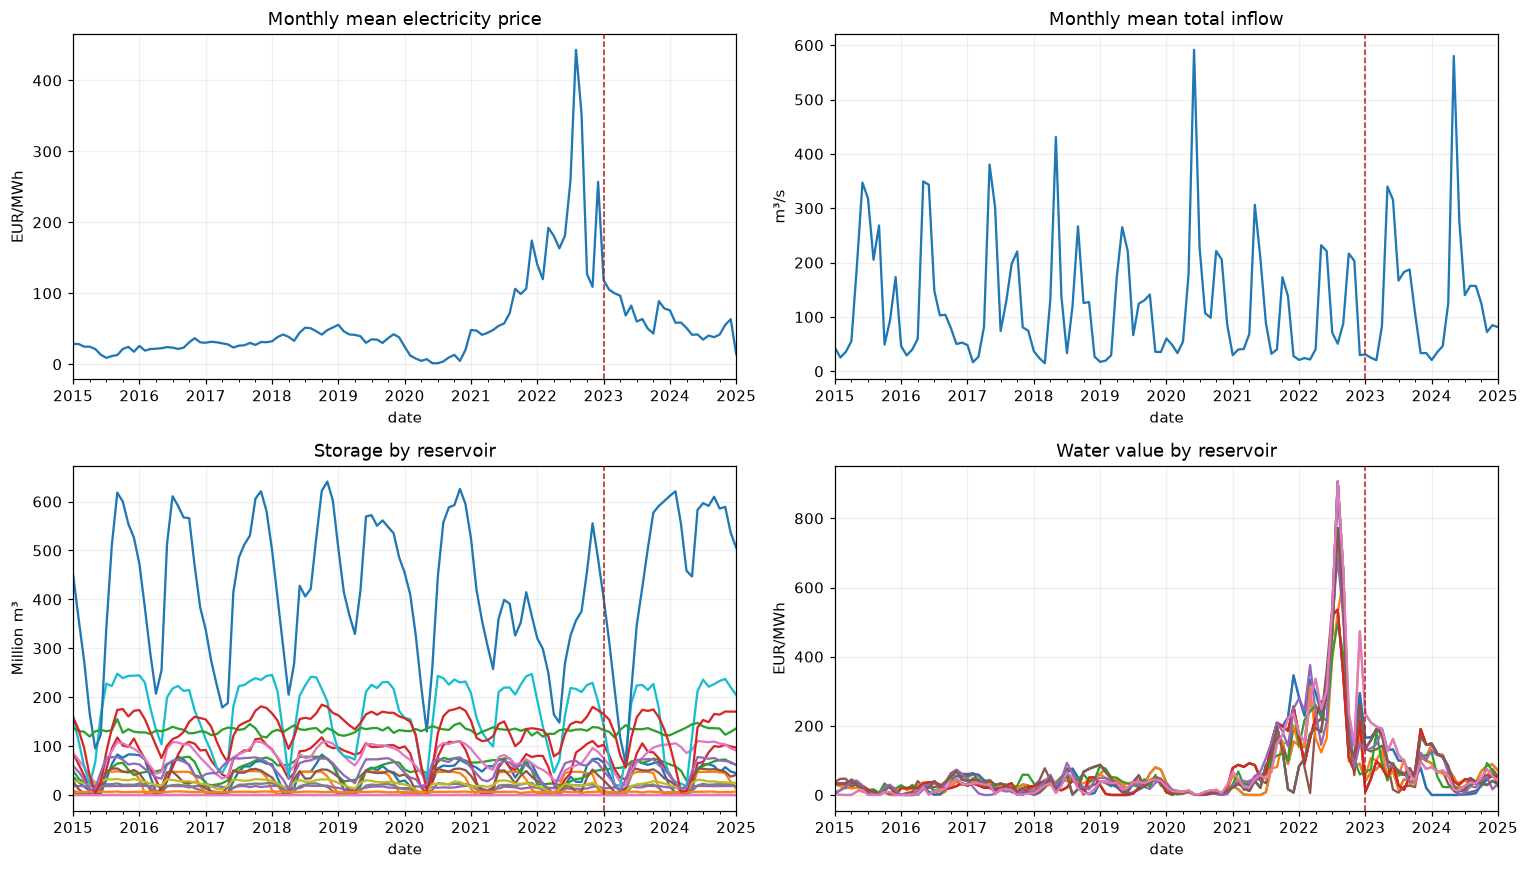

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
price.iloc[:, 0].resample('MS').mean().plot(ax=axes[0, 0], title='Monthly mean electricity price')
axes[0, 0].set_ylabel('EUR/MWh')
inflow.sum(axis=1, min_count=1).resample('MS').mean().plot(ax=axes[0, 1], title='Monthly mean total inflow')
axes[0, 1].set_ylabel('m³/s')
volume.resample('MS').mean().plot(ax=axes[1, 0], legend=False, title='Storage by reservoir')
axes[1, 0].set_ylabel('Million m³')
water.resample('MS').mean().plot(ax=axes[1, 1], legend=False, title='Water value by reservoir')
axes[1, 1].set_ylabel('EUR/MWh')
for ax in axes.ravel():
    ax.axvline(TEST_START, color='firebrick', linestyle='--', linewidth=1)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Seasonal patterns and distributions
Monthly and hourly profiles summarize seasonality across years. Histograms show the raw distribution without clipping outliers. The total inflow sums the reservoir and river inputs, so it is a descriptive system-level measure.

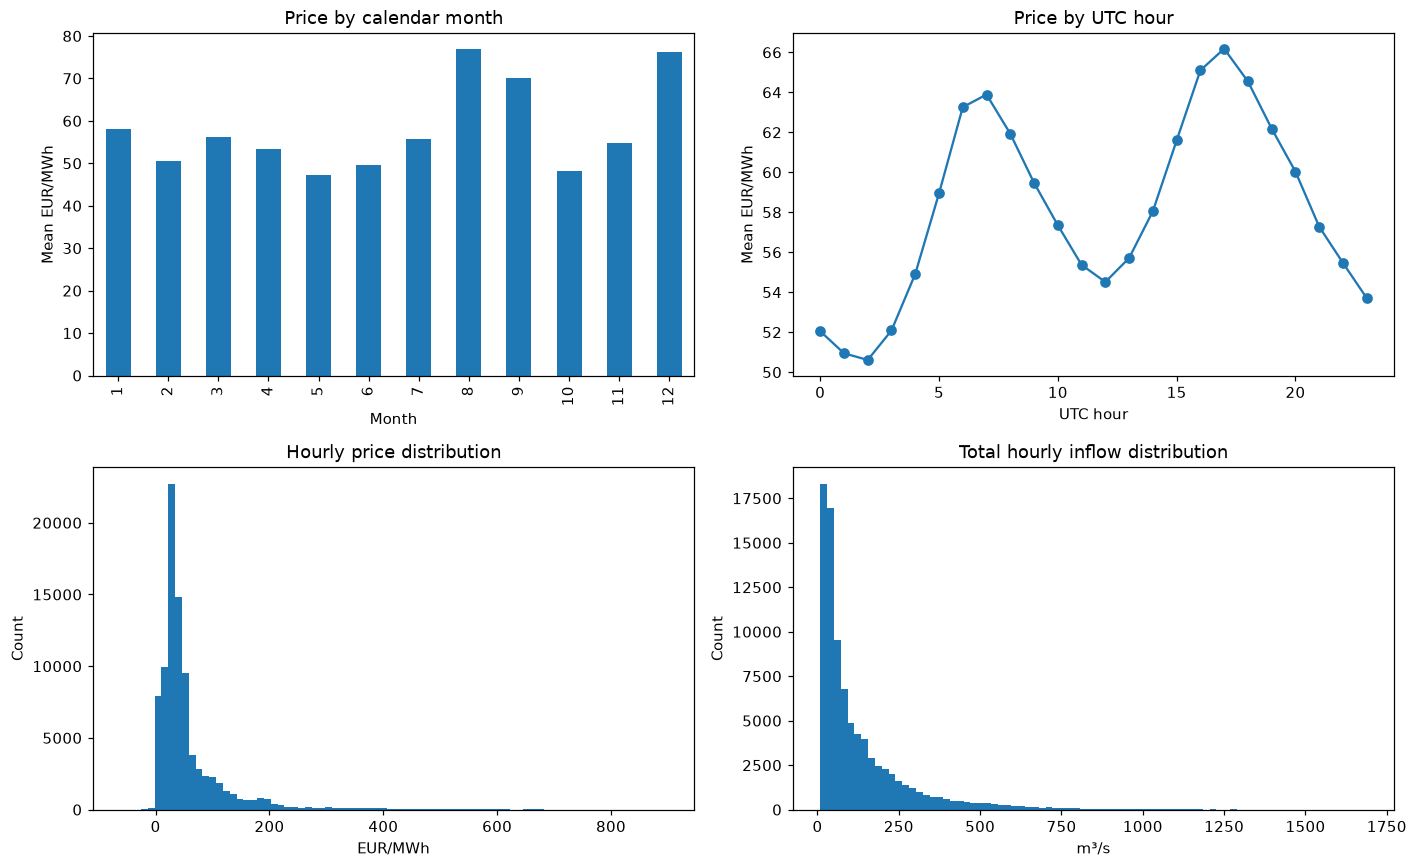

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
price.iloc[:, 0].groupby(price.index.month).mean().plot.bar(ax=axes[0, 0], title='Price by calendar month')
axes[0, 0].set(xlabel='Month', ylabel='Mean EUR/MWh')
price.iloc[:, 0].groupby(price.index.hour).mean().plot(ax=axes[0, 1], marker='o', title='Price by UTC hour')
axes[0, 1].set(xlabel='UTC hour', ylabel='Mean EUR/MWh')
axes[1, 0].hist(price.iloc[:, 0].dropna(), bins=80)
axes[1, 0].set(title='Hourly price distribution', xlabel='EUR/MWh', ylabel='Count')
axes[1, 1].hist(inflow.sum(axis=1, min_count=1).dropna(), bins=80)
axes[1, 1].set(title='Total hourly inflow distribution', xlabel='m³/s', ylabel='Count')
plt.tight_layout()
plt.show()

## 5. Generator activity and class balance
ON/OFF imbalance affects accuracy and confusion matrices. Weekly horizons overlap, so these are frequencies of **case decisions**, not independent observations of physical operation. Each case has 168 hourly decisions per generator.

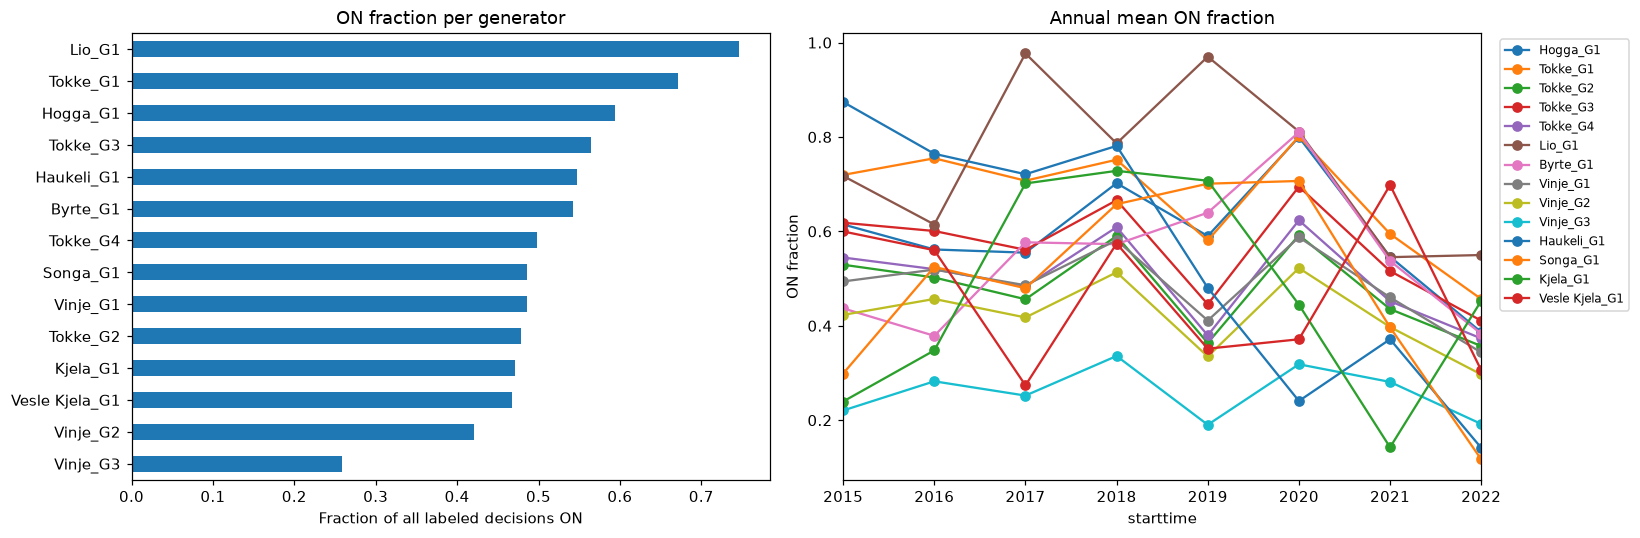

,ON,OFF
Hogga_G1,291867,199029
Tokke_G1,329387,161509
Tokke_G2,234822,256074
Tokke_G3,276994,213902
Tokke_G4,244562,246334
Lio_G1,366470,124426
Byrte_G1,266067,224829
Vinje_G1,238274,252622
Vinje_G2,206357,284539
Vinje_G3,127215,363681


In [5]:
activity = pd.DataFrame(y.mean(axis=1), index=pd.DatetimeIndex(labels['starttime']), columns=generators)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
activity.mean().sort_values().plot.barh(ax=axes[0], title='ON fraction per generator')
axes[0].set_xlabel('Fraction of all labeled decisions ON')
activity.resample('YS').mean().plot(ax=axes[1], title='Annual mean ON fraction', marker='o')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
axes[1].set_ylabel('ON fraction')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'ON': y.sum(axis=(0, 1)),
                      'OFF': y.shape[0] * HORIZON - y.sum(axis=(0, 1))}, index=generators))

## 6. Correlation matrices
Pearson correlation describes linear association, not causation. Aggregations and time dependence can strongly affect these values. The summary matrix aligns daily mean price/inflow and daily reservoir inputs to the case start date, with the mean commitment over the following week. This is exploratory alignment, not the prepared model's feature matrix.

The reservoir matrix uses daily storage observations. The generator matrix correlates each case's weekly ON fractions. Constant columns have undefined correlation and appear gray.

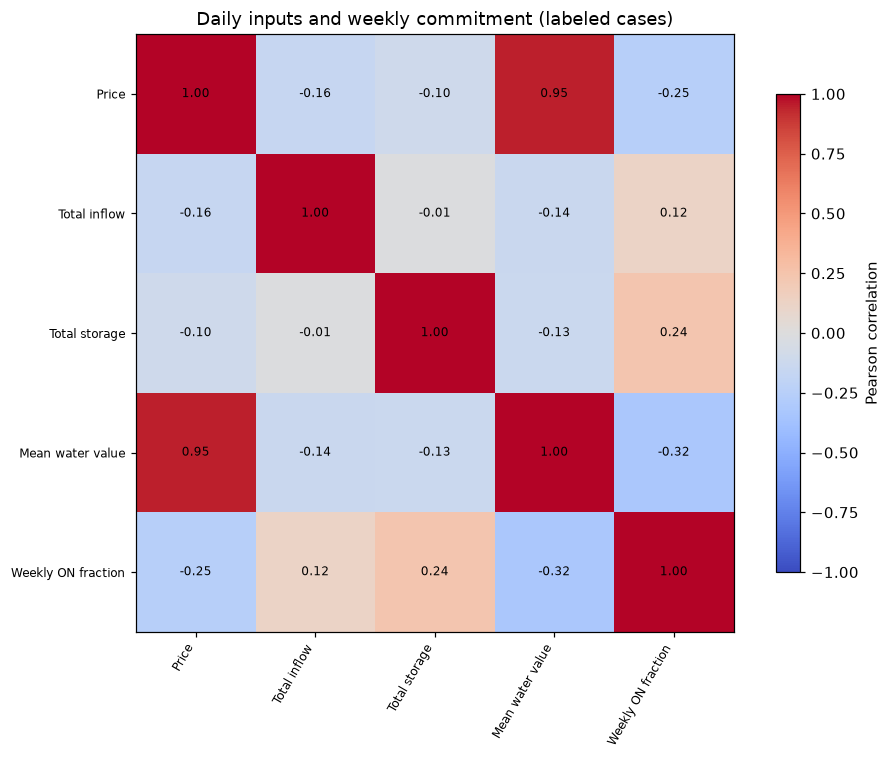

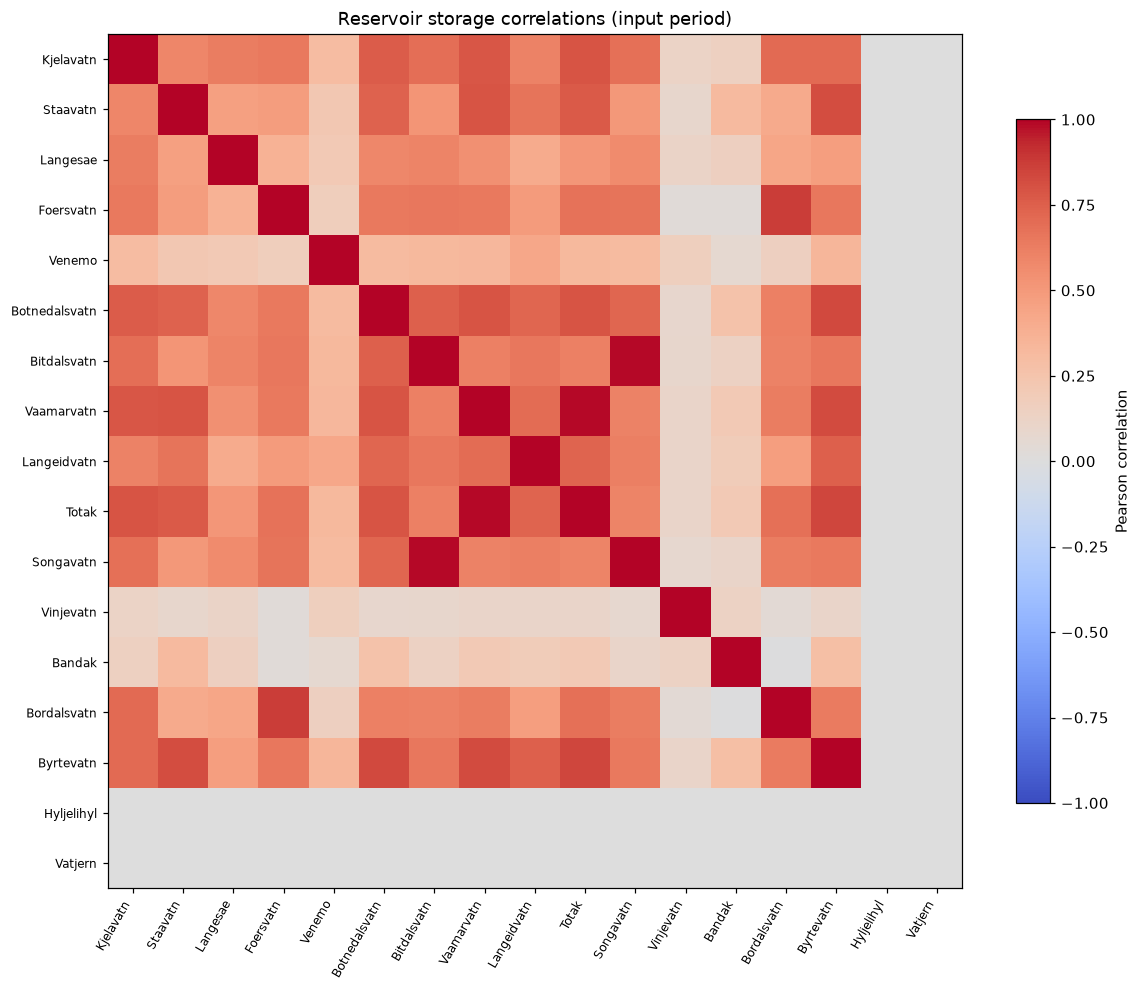

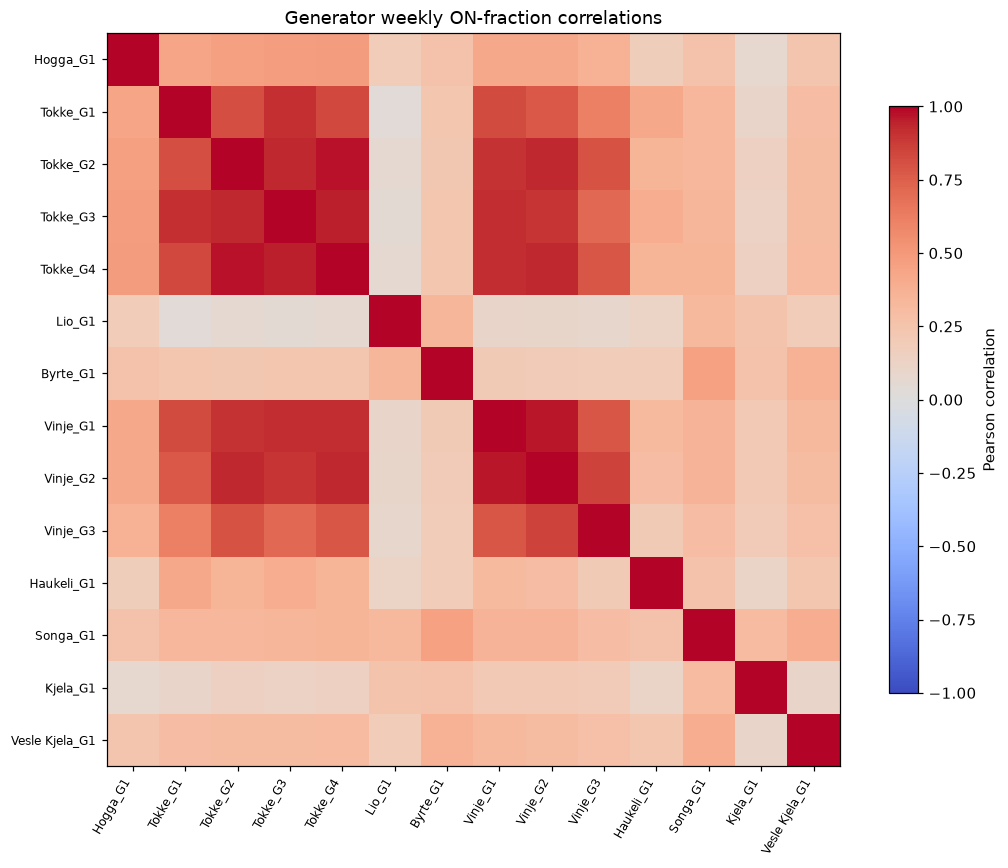

In [6]:
def correlation_plot(frame, title, figsize=(10, 8), annotate=False):
    corr = frame.corr()
    fig, ax = plt.subplots(figsize=figsize)
    cmap = plt.get_cmap('coolwarm').copy()
    cmap.set_bad('#dddddd')
    im = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1, cmap=cmap)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
    if annotate:
        for i in range(len(corr)):
            for j in range(len(corr)):
                value = corr.iloc[i, j]
                ax.text(j, i, f'{value:.2f}' if np.isfinite(value) else 'NA', ha='center', va='center', fontsize=8)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='Pearson correlation', shrink=0.8)
    fig.tight_layout()
    plt.show()
    return corr

summary = pd.DataFrame({
    'Price': price.iloc[:, 0].resample('D').mean(),
    'Total inflow': inflow.sum(axis=1, min_count=1).resample('D').mean(),
    'Total storage': volume.sum(axis=1, min_count=1),
    'Mean water value': water.mean(axis=1),
}).reindex(activity.index)
summary['Weekly ON fraction'] = activity.mean(axis=1)
summary_corr = correlation_plot(summary, 'Daily inputs and weekly commitment (labeled cases)', (9, 7), annotate=True)
storage_corr = correlation_plot(volume, 'Reservoir storage correlations (input period)', (11, 9))
generator_corr = correlation_plot(activity, 'Generator weekly ON-fraction correlations', (10, 8))

## 7. Relationships and an example weekly schedule
Compare price with water value and commitment. The example uses the first labeled case and displays the original binary labels; it is not a model prediction.

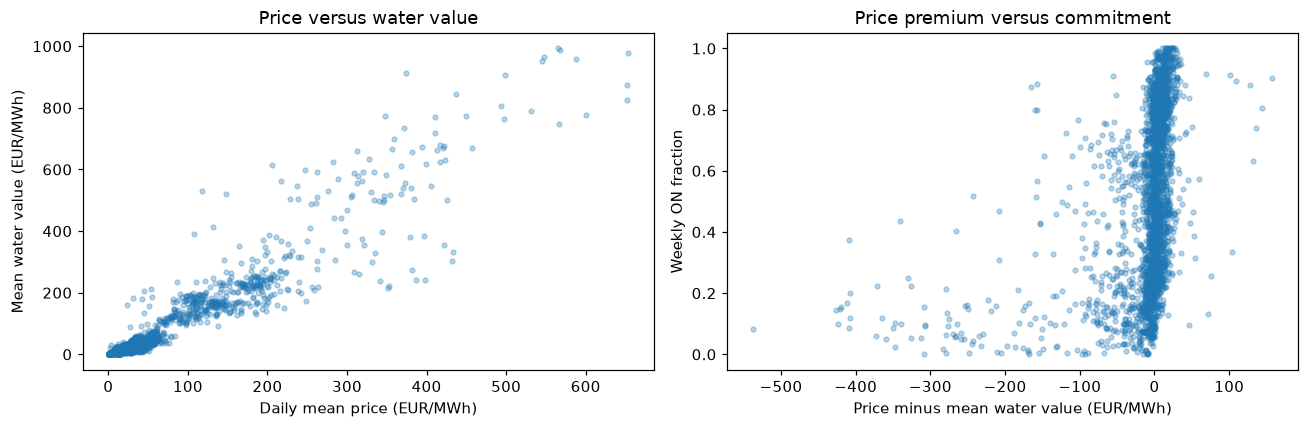

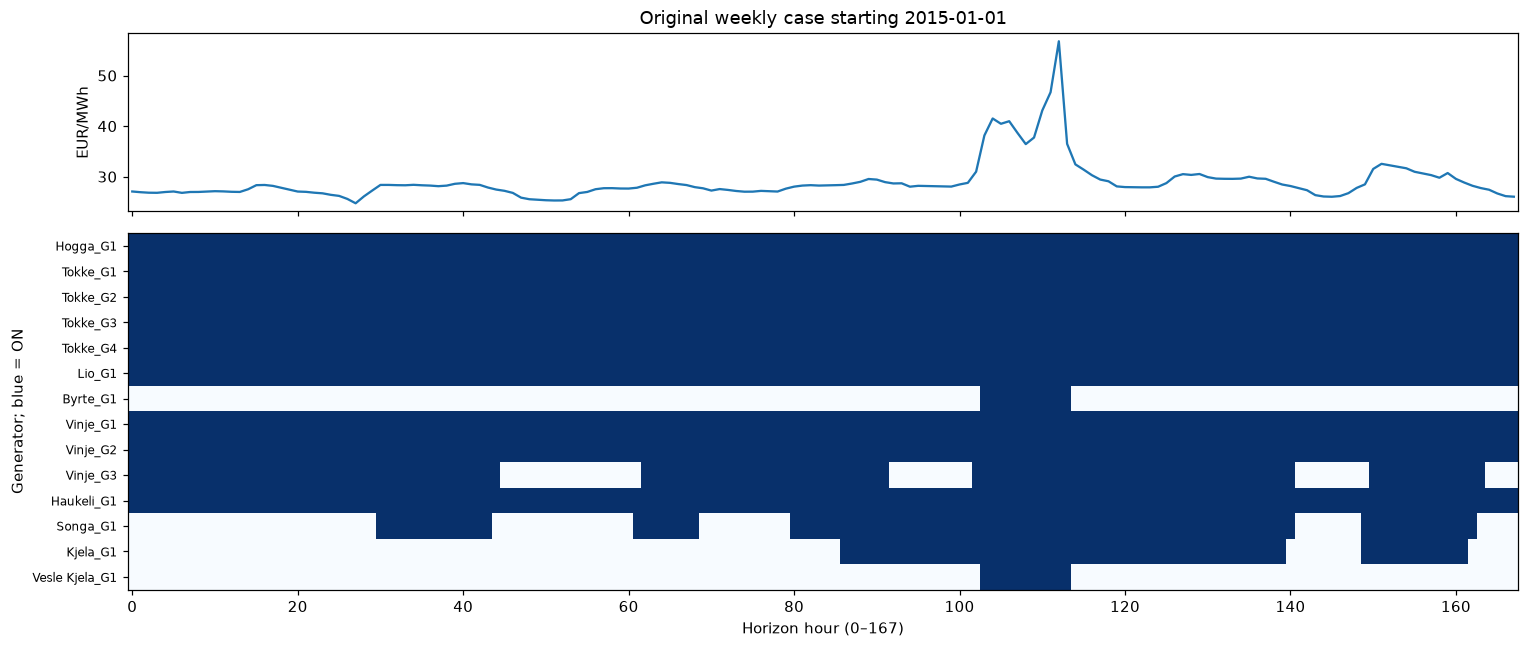

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(summary['Price'], summary['Mean water value'], s=10, alpha=0.3)
axes[0].set(xlabel='Daily mean price (EUR/MWh)', ylabel='Mean water value (EUR/MWh)', title='Price versus water value')
axes[1].scatter(summary['Price'] - summary['Mean water value'], summary['Weekly ON fraction'], s=10, alpha=0.3)
axes[1].set(xlabel='Price minus mean water value (EUR/MWh)', ylabel='Weekly ON fraction', title='Price premium versus commitment')
plt.tight_layout()
plt.show()

CASE_INDEX = 0
start = labels.iloc[CASE_INDEX]['starttime']
timestamps = pd.date_range(start, periods=HORIZON, freq='h')
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
axes[0].plot(np.arange(HORIZON), price.reindex(timestamps).iloc[:, 0])
axes[0].set(ylabel='EUR/MWh', title=f'Original weekly case starting {start.date()}')
axes[1].imshow(y[CASE_INDEX].T, aspect='auto', interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
axes[1].set_yticks(range(len(generators)), generators, fontsize=8)
axes[1].set(xlabel='Horizon hour (0–167)', ylabel='Generator; blue = ON')
plt.tight_layout()
plt.show()

## 8. Optional confusion matrices from existing validation predictions
A confusion matrix requires **true labels and model predictions**; raw inputs alone cannot provide it. This cell never trains a model. If `generated/baseline/validation_predictions.csv` exists from the earlier baseline run, join its probabilities to original labels by `Run No` and compute matrices at threshold 0.5. Otherwise, explain the missing input and skip the section.

Set `PREDICTIONS_PATH` to another validation CSV if needed. It must contain `Run No` and all target columns, with one row per held-out case. Use only out-of-sample predictions. Hidden Kaggle test labels are unavailable. Changing the threshold changes confusion counts; the assignment's micro ROC-AUC evaluates the probabilities without this threshold.

The training notebook now keeps results inline and does not automatically export validation predictions. This optional section can still read an existing predictions file; fresh confusion matrices are also displayed directly in `train_preprocessed.ipynb`.

In [8]:
PREDICTIONS_PATH = PROJECT_DIR / 'generated/baseline/validation_predictions.csv'
THRESHOLD = 0.5
assert 0 <= THRESHOLD <= 1
if not PREDICTIONS_PATH.exists():
    print('Confusion matrices skipped: no saved validation predictions at', PREDICTIONS_PATH)
    print('Provide out-of-sample probabilities with Run No and all target columns to enable this section.')
else:
    prediction_frame = pd.read_csv(PREDICTIONS_PATH)
    assert prediction_frame['Run No'].is_unique and len(prediction_frame) > 0
    assert set(target_columns).issubset(prediction_frame.columns)
    assert set(prediction_frame['Run No']).issubset(set(labels['Run No']))
    actual = labels.set_index('Run No').loc[prediction_frame['Run No']]
    probabilities = prediction_frame[canonical_columns].to_numpy(dtype=float)
    truth = actual[canonical_columns].to_numpy(dtype=np.uint8)
    assert truth.shape == probabilities.shape
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    decisions = (probabilities >= THRESHOLD).astype(np.uint8)
    print(f'Evaluating {len(actual)} saved cases, {actual.starttime.min()} to {actual.starttime.max()}')
    print(f'Micro ROC-AUC: {roc_auc_score(truth.ravel(), probabilities.ravel()):.5f}')
    print('Rows are actual classes; columns are predicted classes. Counts include overlapping weekly cases.')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, norm, title in zip(axes, [None, 'true'], ['All decisions: counts', 'All decisions: normalized by actual class']):
        cm = confusion_matrix(truth.ravel(), decisions.ravel(), labels=[0, 1], normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=['OFF', 'ON']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d' if norm is None else '.3f')
        ax.set_title(title)
    plt.tight_layout()
    plt.show()
    true_cube = truth.reshape(len(actual), len(generators), HORIZON)
    pred_cube = decisions.reshape(len(actual), len(generators), HORIZON)
    fig, axes = plt.subplots(4, 4, figsize=(13, 12))
    for j, ax in enumerate(axes.ravel()):
        if j >= len(generators):
            ax.set_visible(False)
            continue
        cm = confusion_matrix(true_cube[:, j].ravel(), pred_cube[:, j].ravel(), labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=['OFF', 'ON']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.set_title(generators[j], fontsize=10)
    fig.suptitle(f'Per-generator confusion counts, probability threshold {THRESHOLD}', y=1.01)
    plt.tight_layout()
    plt.show()

Confusion matrices skipped: no saved validation predictions at /Users/mjosefsen/Documents/NTNU/TDT4173/github/generated/baseline/validation_predictions.csv
Provide out-of-sample probabilities with Run No and all target columns to enable this section.


## 9. Missing values and missing rows in the original data
This section rereads the **original files before resampling or filling missing values**. By default, it audits **2015–2022**, the labeled training-data period. Change `MISSING_START` and `MISSING_END` below to inspect another period; the end date is exclusive. It can run independently of the earlier analysis cells.

These counts distinguish different problems:
- **Missing cells**: empty fields, whitespace-only strings, or pandas-recognized NA values in the rows that exist. Zero is a valid value, not missing.
- **Rows with missing cells**: existing rows containing one or more missing fields. **Rows with all data missing** excludes the timestamp and case ID, so it detects timestamp-only records.
- **Missing timestamp slots**: expected hourly/daily observations for which no row exists, including gaps at the requested period boundaries. This is separate from blank cells in an existing row. Hourly coverage counts an hour as present if it has at least one observation; it does not audit quarter-hour completeness.
- **Duplicate timestamp rows**: extra rows at an identical timestamp. **Infinite numeric cells** are reported separately, rather than counted as NA.

Rows with an invalid/missing timestamp cannot be assigned to the requested period, so their count is reported separately for the **whole file**. Unit-commitment coverage is capped at 2023-01-01 because later labels were intentionally withheld. Optional minimum-flow/volume files are included if present.

The summary, per-column counts, affected-row examples, and timestamp-gap examples are displayed below and remain available as DataFrames in this notebook. No reports are written to disk.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MISSING_START = pd.Timestamp('2015-01-01', tz='UTC')
MISSING_END = pd.Timestamp('2023-01-01', tz='UTC')  # Exclusive: includes all of 2022.
assert MISSING_START < MISSING_END
AUDIT_ROOT = next((p.resolve() for p in [Path.cwd(), Path.cwd() / 'sintef_project']
                   if (p / 'data/kernel').exists()), None)
if AUDIT_ROOT is None:
    raise FileNotFoundError('Run from sintef_project or set AUDIT_ROOT explicitly.')

# name, relative source file, timestamp column, expected frequency, label-file flag
MISSING_TABLES = [
    ('Market price', 'data/kernel/Historical_day_ahead_price_2015_2025.csv', 'date', 'h', False),
    ('Inflow', 'data/kernel/Historical_inflow_1958_2025.csv', 'date', 'h', False),
    ('Storage', 'data/kernel/Historical_volume_2015_2024.csv', 'date', 'D', False),
    ('Water value', 'data/kernel/Synthetic_water_value_2015_2024.csv', 'date', 'D', False),
    ('UC labels', 'data/kernel/Unit_commitment_decisions.csv', 'starttime', 'D', True),
    ('Minimum volume', 'data/extended/Constraint_min_volume.csv', 'date', 'h', False),
    ('Minimum flow', 'data/extended/Constraint_min_flow.csv', 'date', 'h', False),
]

def summarize_missing_frame(frame, timestamp_col, frequency, start, end):
    """Audit scoped original rows; do not impute or create synthetic data rows."""
    frame = frame.replace(r'^\s*$', np.nan, regex=True)
    dates = pd.to_datetime(frame[timestamp_col], utc=True, errors='coerce')
    frame = frame.loc[dates.ge(start) & dates.lt(end)].copy()
    dates = dates.loc[frame.index]
    missing = frame.isna()
    value_columns = [c for c in frame if c not in {timestamp_col, 'Run No'}]
    data_missing = missing[value_columns]
    expected = pd.date_range(start, end, freq=frequency, inclusive='left')
    observed = pd.DatetimeIndex(dates).floor(frequency).unique()
    absent = expected.difference(observed)
    numeric = frame.select_dtypes(include='number')
    infinite = np.isinf(numeric.to_numpy(dtype=float)).sum() if len(numeric.columns) else 0
    counts = {
        'rows_present': len(frame), 'columns': len(frame.columns),
        'missing_cells': int(missing.to_numpy().sum()),
        'missing_cells_pct': 100 * missing.to_numpy().sum() / frame.size if frame.size else np.nan,
        'rows_with_missing_cells': int(missing.any(axis=1).sum()),
        'rows_with_all_data_missing': int(data_missing.all(axis=1).sum()) if value_columns else 0,
        'columns_with_missing_cells': int(missing.any(axis=0).sum()),
        'expected_timestamp_slots': len(expected), 'missing_timestamp_slots': len(absent),
        'duplicate_timestamp_rows': int(dates.duplicated().sum()),
        'infinite_numeric_cells': int(infinite),
    }
    per_column = pd.DataFrame({'column': frame.columns,
                               'missing_values': missing.sum().to_numpy(),
                               'missing_pct': missing.mean().to_numpy() * 100})
    examples = []
    for idx in frame.index[missing.any(axis=1)][:5]:
        columns = missing.columns[missing.loc[idx]].tolist()
        examples.append({'timestamp': str(dates.loc[idx]), 'missing_values_in_row': len(columns),
                         'missing_columns': ', '.join(columns[:8]) + (' …' if len(columns) > 8 else '')})
    return counts, per_column, examples, absent

missing_summaries, missing_columns_all, affected_examples, gap_examples = [], [], [], []
for table_name, relative_path, timestamp_col, frequency, is_labels in MISSING_TABLES:
    path = AUDIT_ROOT / relative_path
    if not path.exists():
        if relative_path.startswith('data/extended/'):
            print('Optional file unavailable, skipped:', relative_path)
            continue
        raise FileNotFoundError(path)
    end = min(MISSING_END, pd.Timestamp('2023-01-01', tz='UTC')) if is_labels else MISSING_END
    if end <= MISSING_START:
        print(f'{table_name}: no released labels in the requested period; skipped.')
        continue
    chunks, invalid_dates = [], 0
    for chunk in pd.read_csv(path, chunksize=10_000):
        dates = pd.to_datetime(chunk[timestamp_col], utc=True, errors='coerce')
        invalid_dates += int(dates.isna().sum())
        # Append even empty selections to retain the source schema for fully absent periods.
        chunks.append(chunk.loc[dates.ge(MISSING_START) & dates.lt(end)])
    original_rows = pd.concat(chunks, ignore_index=True)
    counts, per_column, examples, gaps = summarize_missing_frame(
        original_rows, timestamp_col, frequency, MISSING_START, end)
    missing_summaries.append({'table': table_name, 'source': relative_path,
                              'audit_start_utc': str(MISSING_START), 'audit_end_exclusive_utc': str(end),
                              **counts, 'invalid_timestamp_rows_whole_file': invalid_dates})
    per_column.insert(0, 'table', table_name)
    missing_columns_all.append(per_column)
    affected_examples.extend([{'table': table_name, **row} for row in examples])
    gap_examples.extend([{'table': table_name, 'missing_timestamp_utc': str(t)} for t in gaps[:5]])

missing_summary = pd.DataFrame(missing_summaries).set_index('table')
missing_by_column = pd.concat(missing_columns_all, ignore_index=True)
missing_row_examples = pd.DataFrame(affected_examples, columns=['table', 'timestamp', 'missing_values_in_row', 'missing_columns'])
missing_timestamp_examples = pd.DataFrame(gap_examples, columns=['table', 'missing_timestamp_utc'])
print(f'Raw-data missingness audit: {MISSING_START.date()} up to {MISSING_END.date()} (exclusive).')
display(missing_summary.drop(columns=['source', 'audit_start_utc', 'audit_end_exclusive_utc']).round(3))


Raw-data missingness audit: 2015-01-01 up to 2023-01-01 (exclusive).


,rows_present,columns,missing_cells,missing_cells_pct,rows_with_missing_cells,rows_with_all_data_missing,columns_with_missing_cells,expected_timestamp_slots,missing_timestamp_slots,duplicate_timestamp_rows,infinite_numeric_cells,invalid_timestamp_rows_whole_file
table,,,,,,,,,,,,
Market price,70128,2,0,0.0,0,0,0,70128,0,0,0,0
Inflow,70128,19,0,0.0,0,0,0,70128,0,0,0,0
Storage,2922,18,0,0.0,0,0,0,2922,0,0,0,0
Water value,2922,18,0,0.0,0,0,0,2922,0,0,0,0
UC labels,2922,2355,0,0.0,0,0,0,2922,0,0,0,0
Minimum volume,70128,4,0,0.0,0,0,0,70128,0,0,0,0
Minimum flow,70128,7,0,0.0,0,0,0,70128,0,0,0,0


Columns with missing values (largest counts first):
No missing cells found in the original rows in this period.
Examples of existing rows with missing cells (up to 5 per table):
None.
Examples of absent timestamp slots (up to 5 per table):
No missing hourly/daily slots in the requested coverage.


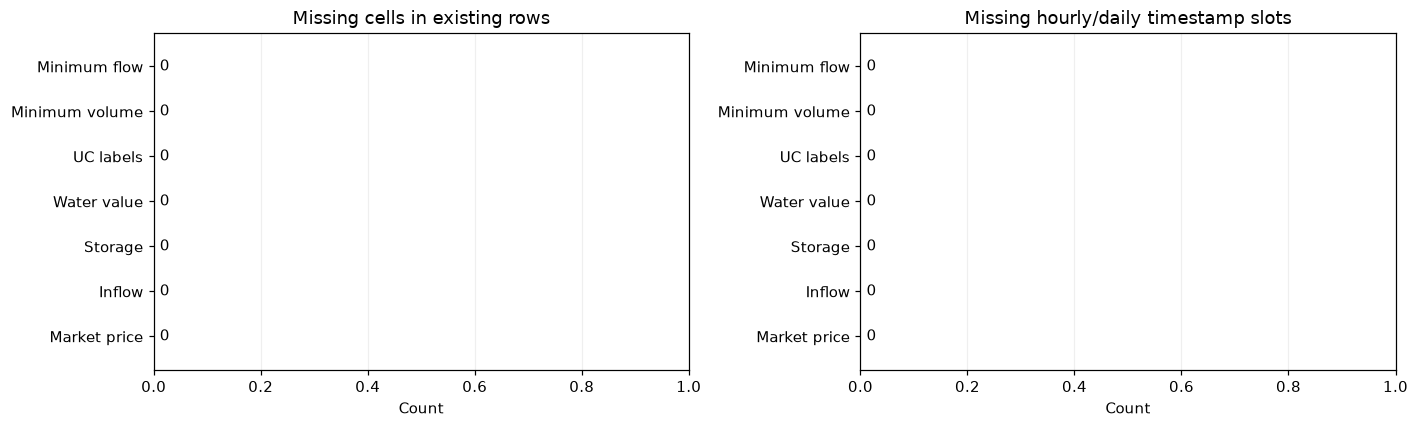

In [10]:
print('Columns with missing values (largest counts first):')
missing_only = missing_by_column.loc[missing_by_column['missing_values'] > 0].sort_values('missing_values', ascending=False)
if missing_only.empty:
    print('No missing cells found in the original rows in this period.')
else:
    display(missing_only.head(30).round(3))
    if len(missing_only) > 30:
        print(f'Showing 30 of {len(missing_only)} affected columns; all counts are available in the missing_by_column DataFrame.')

print('Examples of existing rows with missing cells (up to 5 per table):')
if missing_row_examples.empty:
    print('None.')
else:
    display(missing_row_examples)
print('Examples of absent timestamp slots (up to 5 per table):')
if missing_timestamp_examples.empty:
    print('No missing hourly/daily slots in the requested coverage.')
else:
    display(missing_timestamp_examples)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, title in [
    (axes[0], 'missing_cells', 'Missing cells in existing rows'),
    (axes[1], 'missing_timestamp_slots', 'Missing hourly/daily timestamp slots'),
]:
    values = missing_summary[column]
    bars = ax.barh(values.index, values.to_numpy(), color='#4477AA')
    ax.bar_label(bars, fmt='%.0f', padding=4)
    ax.set(title=title, xlabel='Count')
    ax.set_xlim(0, max(1, float(values.max()) * 1.2))
    ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()